In [8]:
from IPython.display import HTML

HTML("""
<div style="
    background-color: #418FDE; 
    border-radius: 10px; 
    padding: 20px; 
    border-left: 8px solid #FDB927; 
    text-align: center;
    box-shadow: 3px 3px 10px rgba(0,0,0,0.3);
">
    <h1 style="color: #FFFFFF; font-family: Arial, sans-serif; margin: 0; text-align: center;">
        ⛷️ Atari Skiing Game: Statistical Investigation
    </h1>
    <p style="color: #FFFFFF; font-size: 16px; margin-top: 10px; text-align: center; font-weight: bold;">
        Analyzing A Random AI Agent's Slalom Gate Performance During a 20-Gate Run
    </p>
</div>
""")

<div style="background-color: #F4F8FD; border-left: 6px solid #418FDE; padding: 15px; border-radius: 8px; margin-bottom: 12px;">
    <h2 style="color: #002B5C; text-align: center;"><strong>Statistical Investigation Question:</strong></h2>
    <h3 style="color: #1B4F9C; text-align: center;">What is the probability that a random AI agent successfully passes through 1–3 slalom gates during a 20-gate run in the Atari Skiing game?</h3>
</div>

<div style="background-color: #F4F8FD; border-left: 6px solid #FDB927; padding: 15px; border-radius: 8px;">
    <h2 style="color: #002B5C; text-align: center;"><strong>Type of Simulation:</strong></h2>
    <h3 style="color: #1B4F9C;">1. <strong>Random Variable ($X$):</strong> My simulation's random variable ($X$) is the total number of slalom gates passed during a 20-gate run. This is a <strong>discrete random variable</strong> because gates are counted in whole numbers (0 through 20); fractional values like half a gate or a quarter of a gate are impossible. Because $n = 20$ and $p = 0.25$ satisfy the Large Counts Condition ($np = 5 \ge 5$ and $n(1-p) = 15 \ge 5$), I am using a continuous normal distribution with a continuity correction ($0.5 \le X \le 3.5$) to approximate this discrete binomial distribution.</h3>
    <h3 style="color: #1B4F9C;">2. <strong>Trials & Outcomes:</strong> Each simulated run consists of $n = 20$ independent trials, where one individual trial is the random AI agent attempting to navigate a single slalom gate. Each trial has two possible outcomes: <strong>Success</strong> (cleanly passing between the gate flags, with probability $p = 0.25$) or <strong>Failure</strong> (missing the gate or hitting a flag/obstacle, with probability $1 - p = 0.75$).</h3>
</div>

In [9]:
import ale_py
import gymnasium as gym

# Register the Arcade Learning Environment (ALE) games.
gym.register_envs(ale_py)
print("ALE/Skiing-v5 environment registered successfully.")

ModuleNotFoundError: No module named 'ale_py'

In [ ]:
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import time

In [3]:
# Create environment.
env = gym.make('ALE/Skiing-v5', render_mode='rgb_array')
observation, info = env.reset()

NameError: name 'gym' is not defined

In [4]:
# Create game window.
fig, ax = plt.subplots(figsize=(6, 8))
ax.axis('off')

# Play game randomly.
total_reward = 0

for step in range(500):
    # Take action.
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    
    # Clear and update display.
    clear_output(wait=True)
    ax.clear()
    ax.imshow(env.render())
    ax.set_title(f"Step: {step} | Reward: {total_reward:.0f}")
    ax.axis('off')
    
    display(fig)
    
    # Add delay to make it visible (adjust this value).
    time.sleep(0.03)  # 30ms delay = ~33 fps
    
    # Reset if game over.
    if terminated or truncated:
        observation, info = env.reset()
        total_reward = 0

plt.close()
env.close()

NameError: name 'plt' is not defined

<h2 style="color: #002B5C; text-align: center;"><strong>Simulation Code (1,000 Runs):</strong></h2>

<div style="background-color: #F4F8FD; border-left: 6px solid #418FDE; padding: 12px; border-radius: 8px; margin-bottom: 10px;">
    <p style="color: #1B4F9C; margin: 0;"><strong>Why a Binomial Model?</strong> While the live Atari environment above visualizes how a random agent steers down the slope, its raw reward output tracks elapsed time and penalties rather than exact gate counts. To measure gate-clearing probability across 1,000 runs, the simulation below models each 20-gate course using a binomial distribution with a baseline random-agent gate success rate of $p = 0.25$.</p>
</div>

<h2 style="color: #002B5C; text-align: center;"><strong>Empirical & Theoretical Probabilities Calculations:</strong></h2>

In [5]:
import numpy as np
import pandas as pd
from scipy.stats import norm

# 1. Set simulation parameters based on Atari Skiing's 20-gate slalom course.
np.random.seed(42)
num_runs = 1000
total_course_gates = 20   # Standard Atari Skiing slalom course has 20 gates.
p_clear_gate = 0.25       # Probability a random AI agent clears a gate without hitting a tree.

# 2. Simulate 1,000 runs (discrete whole-number gate counts centered around mu = 5.0).
gates_passed = np.random.binomial(n=total_course_gates, p=p_clear_gate, size=num_runs)

# 3. Create Pandas DataFrame.
df = pd.DataFrame({
    'run_id': np.arange(1, num_runs + 1),
    'gates_passed': gates_passed,
    'in_target_range_1_to_3': (gates_passed >= 1) & (gates_passed <= 3)
})

# 4. Compute Empirical vs. Theoretical Normal Model statistics.
mean_gates = df['gates_passed'].mean()
std_gates = df['gates_passed'].std(ddof=1)
empirical_prob = df['in_target_range_1_to_3'].mean()

# Normal approximation with continuity correction: P(0.5 <= X <= 3.5).
theoretical_normal_prob = (
    norm.cdf(3.5, loc=mean_gates, scale=std_gates)
    - norm.cdf(0.5, loc=mean_gates, scale=std_gates)
)

print(f"Sample Mean (μ): {mean_gates:.2f} gates")
print(f"Sample Standard Deviation (σ): {std_gates:.2f} gates")
print(f"Empirical Probability P(1 <= Gates <= 3): {empirical_prob:.4f} ({empirical_prob:.2%})")
print(f"Theoretical Normal Probability P(0.5 <= X <= 3.5): {theoretical_normal_prob:.4f} ({theoretical_normal_prob:.2%})")

# 5. Save dataset to CSV.
df.to_csv("atari_skiing_gates_simulation_1000.csv", index=False)
print("Data successfully saved to 'atari_skiing_gates_simulation_1000.csv'")

Sample Mean (μ): 4.94 gates
Sample Standard Deviation (σ): 1.94 gates
Empirical Probability P(1 <= Gates <= 3): 0.2430 (24.30%)
Theoretical Normal Probability P(0.5 <= X <= 3.5): 0.2172 (21.72%)
Data successfully saved to 'atari_skiing_gates_simulation_1000.csv'


<h2 style="color: #002B5C; text-align: center;"><strong>Mean & Standard Deviation Calculations:</strong></h2>

In [6]:
# Import necessary libraries.
import numpy as np
import pandas as pd

# 1. Load your simulation data.
df = pd.read_csv("atari_skiing_gates_simulation_1000.csv")
x = df['gates_passed']

# 2. Sample size (n).
n = len(x)

# 3. Sample Mean formula: x̄ = (Σ x_i) / n.
sum_x = sum(x)
x_bar = sum_x / n

# 4. Sample Standard Deviation formula: s = sqrt( Σ(x_i - x̄)^2 / (n - 1) ).
squared_deviations = [(x_i - x_bar) ** 2 for x_i in x]
sum_squared_deviations = sum(squared_deviations)
s = np.sqrt(sum_squared_deviations / (n - 1))

# 5. Display step-by-step values and final results.
print(f"Sample Size (n): {n}")
print(f"Sum of Gate Counts (Σ x_i): {sum_x}")
print(f"Sample Mean (x̄): {x_bar:.4f} gates")
print(f"Sum of Squared Deviations Σ(x_i - x̄)²: {sum_squared_deviations:.4f}")
print(f"Sample Standard Deviation (s): {s:.4f} gates")

Sample Size (n): 1000
Sum of Gate Counts (Σ x_i): 4944
Sample Mean (x̄): 4.9440 gates
Sum of Squared Deviations Σ(x_i - x̄)²: 3752.8640
Sample Standard Deviation (s): 1.9382 gates


<h2 style="color: #002B5C; text-align: center;"><strong>Conclusion:</strong></h2>

<h3 style="color: #002B5C; text-align: center;"><strong>Simulation Graph:</strong></h3>

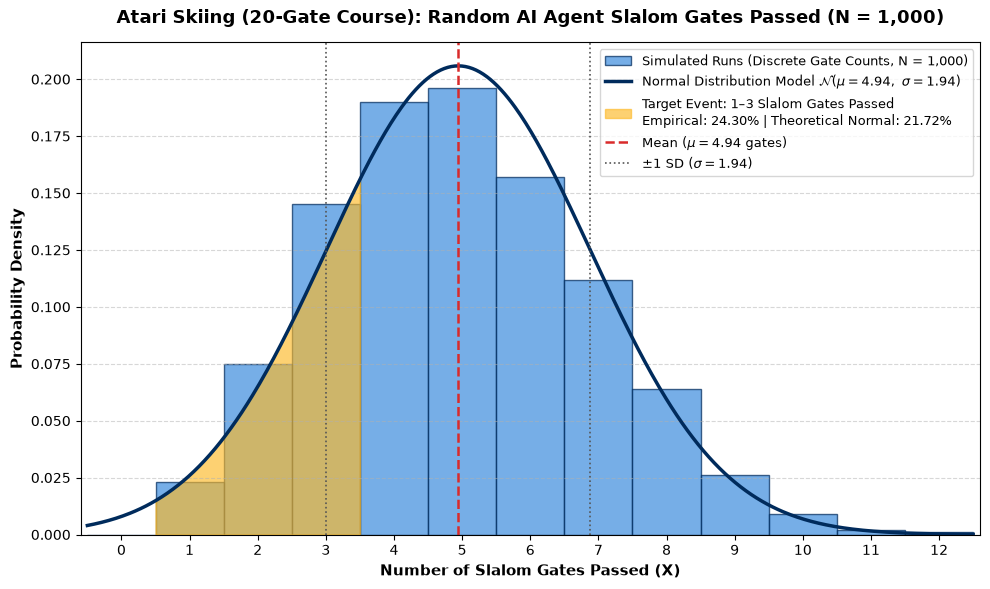

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# 1. Load simulation data.
df = pd.read_csv("atari_skiing_gates_simulation_1000.csv")
gates = df['gates_passed']

mean_gates = gates.mean()
std_gates = gates.std(ddof=1)
emp_prob = df['in_target_range_1_to_3'].mean()
theo_prob = norm.cdf(3.5, loc=mean_gates, scale=std_gates) - norm.cdf(0.5, loc=mean_gates, scale=std_gates)

# 2. Initialize figure.
fig, ax = plt.subplots(figsize=(10, 6))

# Center histogram bars directly over integer gate counts (0, 1, 2, ..., 20).
min_g, max_g = 0, max(12, gates.max())
bins = np.arange(min_g - 0.5, max_g + 1.5, 1)

ax.hist(
    gates,
    bins=bins,
    density=True,
    color='#418FDE',
    edgecolor='#002B5C',
    alpha=0.72,
    label='Simulated Runs (Discrete Gate Counts, N = 1,000)'
)

# 3. Overlay the Normal Distribution Bell Curve.
x = np.linspace(-0.5, max_g + 0.5, 500)
y = norm.pdf(x, loc=mean_gates, scale=std_gates)
ax.plot(
    x, y,
    color='#002B5C',
    linewidth=2.5,
    label=f'Normal Distribution Model $\\mathcal{{N}}(\\mu={mean_gates:.2f},\\ \\sigma={std_gates:.2f})$'
)

# 4. Shade the target region: 1 to 3 gates (0.5 to 3.5 with continuity correction).
x_target = np.linspace(0.5, 3.5, 300)
y_target = norm.pdf(x_target, loc=mean_gates, scale=std_gates)
ax.fill_between(
    x_target, y_target,
    color='#FDB927',
    alpha=0.65,
    label=f'Target Event: 1–3 Slalom Gates Passed\nEmpirical: {emp_prob:.2%} | Theoretical Normal: {theo_prob:.2%}'
)

# 5. Add reference lines for Mean and ±1 SD.
ax.axvline(mean_gates, color='#D92B2B', linestyle='--', linewidth=1.8, label=f'Mean ($\\mu = {mean_gates:.2f}$ gates)')
ax.axvline(mean_gates - std_gates, color='#555555', linestyle=':', linewidth=1.2, label=f'±1 SD ($\\sigma = {std_gates:.2f}$)')
ax.axvline(mean_gates + std_gates, color='#555555', linestyle=':', linewidth=1.2)

# 6. Titles, axis labels, and formatting.
ax.set_title(
    'Atari Skiing (20-Gate Course): Random AI Agent Slalom Gates Passed (N = 1,000)',
    fontsize=13, fontweight='bold', pad=14
)
ax.set_xlabel('Number of Slalom Gates Passed (X)', fontsize=11, fontweight='bold')
ax.set_ylabel('Probability Density', fontsize=11, fontweight='bold')
ax.set_xticks(range(min_g, max_g + 1))
ax.set_xlim(-0.6, max_g + 0.6)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='upper right', frameon=True, fontsize=9.5)

plt.tight_layout()
plt.savefig("atari_skiing_normal_distribution.png", dpi=300)
plt.show()

<h3 style="color: #1B4F9C;">This simulation's theoretical probability is approximately 21.72%. The empirical probability is about 24.30%. </h3>

<h3 style="color: #1B4F9C;">The graph above holds many individual answers to my statistical question. The empirical and theoretical probabilities show that the chances of the AI agent passing through 1-3 slalom gates is pretty slim, considering the fact that both probabilities are below 25%. Keep in mind that most runs cluster to 5 gates.</h3>